# Pricing motor insurance: frequency × severity on French MTPL data

A motor third-party liability (MTPL) insurer must charge each policy its **pure premium**: the expected cost of its claims per year. This notebook estimates it on `freMTPL2` (678,013 French policies, 26,639 claims). We use two datasets:

-   **freMTPL2freq**: One row per policy. Contains relevant features such as characteristics on the car, on the driver and on the geographical zone. It also contains a column `ClaimNb` (number of claims). 678,013 rows, 12 columns.
-  **freMTPL2sev** : One row per claim, with ID and import of the claim. 26,639 rows, 2 columns.

The main idea is to split the cost of a claim as **frequency x severity**, estimating each factor independently. We proceed in **four** steps:

1. **Data cleaning**: The two raw tables disagree on the number of claims, and the way they disagree decides the claim counts.
2. **Frequency**: How many claims per year. Poisson GLM against gradient boosting (LightGBM).
3. **Severity**: How much one claim costs. Gamma GLM, with large claims handled separately.
4. **Pure premium** = frequency × severity, and how well each model ranks and prices the risks of a test set it has never seen.

The theory behind each step is explained in the `README` file.

## 1. Import necessary packages

In [2]:
import urllib.request
from pathlib import Path

import lightgbm as lgb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rdata
import statsmodels.api as sm
from sklearn.metrics import mean_gamma_deviance, mean_poisson_deviance, mean_tweedie_deviance

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 20)

SEED = 42
DATA_DIR = Path("data")
FIGURES_DIR = Path("figures")
FIGURES_DIR.mkdir(exist_ok=True)

## 2. Load the dataset

The data come from the CASdatasets R package. We download the **original 2017 release** from its GitHub repository at a fixed commit, so that the data cannot change. The first run downloads and converts the two R files; later runs read them from `data/`.

In [3]:
# Original 2017 release of freMTPL2, at a fixed commit of the CASdatasets repository.
CAS_URL = "https://raw.githubusercontent.com/dutangc/CASdatasets/9aa07b9d7f07c6d877674decc95503bf1f0fd8c5/pkg/data/{name}.rda"


def load_table(name: str) -> pd.DataFrame:
    """Download one table once, convert it from R format, then read it from a local parquet copy."""
    cache = DATA_DIR / f"{name}.parquet"
    if not cache.exists():
        DATA_DIR.mkdir(exist_ok=True)
        rda_file = DATA_DIR / f"{name}.rda"
        urllib.request.urlretrieve(CAS_URL.format(name=name), rda_file)
        rdata.read_rda(rda_file)[name].reset_index(drop=True).to_parquet(cache)
        rda_file.unlink()
    return pd.read_parquet(cache)


policies = load_table("freMTPL2freq")  # one row per policy
claims = load_table("freMTPL2sev")     # one row per claim

print(f"policies: {policies.shape[0]:,} rows x {policies.shape[1]} columns, missing values: {policies.isna().sum().sum()}")
print(f"claims:   {claims.shape[0]:,} rows x {claims.shape[1]} columns, missing values: {claims.isna().sum().sum()}")
policies.head()

policies: 678,013 rows x 12 columns, missing values: 0
claims:   26,639 rows x 2 columns, missing values: 0


,IDpol,ClaimNb,Exposure,Area,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region
0,1.0,1.0,0.10,D,5,0,55,50,B12,Regular,1217,R82
1,3.0,1.0,0.77,D,5,0,55,50,B12,Regular,1217,R82
2,5.0,1.0,0.75,B,6,2,52,50,B12,Diesel,54,R22
3,10.0,1.0,0.09,B,7,0,46,50,B12,Diesel,76,R72
4,11.0,1.0,0.84,B,7,0,46,50,B12,Diesel,76,R72


In [4]:
claims.head()

,IDpol,ClaimAmount
0,1552,995.20
1,1010996,1128.12
2,4024277,1851.11
3,4007252,1204.00
4,4046424,1204.00


| Variable | Meaning                                                                                |
|---|----------------------------------------------------------------------------------------|
| `IDpol` | policy id, links the two tables                                                        |
| `ClaimNb` | number of claims in the exposure period                                                |
| `Exposure` | how long the policy was observed, in years                                             |
| `VehPower`, `VehAge`, `VehBrand`, `VehGas` | power (ordered categorical), age (years), brand (anonymised), fuel of the car                              |
| `DrivAge` | age of the driver                                                                      |
| `BonusMalus` | bonus-malus coefficient × 100: from 50 (maximum bonus) up; new drivers start at 100    |
| `Area`, `Density`, `Region` | density class (A rural … F urban), inhabitants per km² and region of the driver's town |
| `ClaimAmount` (claims table) | cost of one claim                                                                      |



## 3. Data cleaning

### 3.1 Keys and types


In [5]:
# IDpol and ClaimNb are stored as floats in the R file: check they are whole numbers, then cast.
assert policies["IDpol"].is_unique #Check that policies are uniquely determined
assert (policies["IDpol"] % 1 == 0).all() and (policies["ClaimNb"] % 1 == 0).all() #Check for errors in ID number of policies and number of claims

INT_COLS = ["IDpol", "ClaimNb", "VehPower", "VehAge", "DrivAge", "BonusMalus", "Density"]
policies[INT_COLS] = policies[INT_COLS].astype("int64") #Convert integer columns in int types
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    policies[col] = policies[col].astype(str).astype("category") #Transform in str first to avoid potential errors
claims["IDpol"] = claims["IDpol"].astype("int64")
print("policies dataset:\n")
print(policies.dtypes.to_string())

print("\n claims dataset:\n")
print(claims.dtypes.to_string())

policies dataset:

IDpol            int64
ClaimNb          int64
Exposure       float64
Area          category
VehPower         int64
VehAge           int64
DrivAge          int64
BonusMalus       int64
VehBrand      category
VehGas        category
Density          int64
Region        category

 claims dataset:

IDpol            int64
ClaimAmount    float64


### 3.2 Initial checks and basic EDA

We start exploring the datasets, both to have a feeling of their contents and to check for inconsistencies/mistakes in the data.

REMARK: We do **NOT** drop duplicate rows in `claims` since they may come from different claims. Without an identification for each event, a person might have had two claims worth the same amount. We also choose not to drop duplicates in `claims` in order to have the same cleaning procedure as in the literature (Wüthrich & Merz, 2023).

In [6]:
#Ranges, tails and rare levels.
print("POLICIES TABLE: \n")

print(policies.drop(columns="IDpol").describe().T[["min", "50%", "max"]])
print("CLAIM COUNTS: \n")
print(policies["ClaimNb"].value_counts().sort_index().to_string())
print(f"Claims according to the policy table: {policies['ClaimNb'].sum()}")
# Rare levels: exposure (years) of the smallest level of each categorical variable.
print("EXPOSURE YEARS OF VARIOUS CATEGORIES: \n")
for col in ["Area", "VehBrand", "VehGas", "Region"]:
    exposure = policies.groupby(col, observed=True)["Exposure"].sum().sort_values()
    print(f"{col}: {len(exposure)} levels, smallest {exposure.index[0]} with {exposure.iloc[0]:,.0f} years of exposure")

# Claims table
print("CLAIM TABLE: \n")
print(claims["ClaimAmount"].describe().round(1).to_string())

POLICIES TABLE: 

                  min     50%       max
ClaimNb      0.000000    0.00     16.00
Exposure     0.002732    0.49      2.01
VehPower     4.000000    6.00     15.00
VehAge       0.000000    6.00    100.00
DrivAge     18.000000   44.00    100.00
BonusMalus  50.000000   50.00    230.00
Density      1.000000  393.00  27000.00
CLAIM COUNTS: 

ClaimNb
0     643953
1      32178
2       1784
3         82
4          7
5          2
6          1
8          1
9          1
11         3
16         1
Claims according to the policy table: 36102
EXPOSURE YEARS OF VARIOUS CATEGORIES: 

Area: 6 levels, smallest F with 8,129 years of exposure
VehBrand: 11 levels, smallest B14 with 2,274 years of exposure
VehGas: 2 levels, smallest Diesel with 170,661 years of exposure
Region: 22 levels, smallest R43 with 564 years of exposure
CLAIM TABLE: 

count      26639.0
mean        2278.5
std        29297.5
min            1.0
25%          686.8
50%         1172.0
75%         1228.1
max      4075400.6


The total number of claims differs between the two datasets: 36,102 according to the `policies` dataset vs 26,384 according to the `claims` one. This is a known issue we discuss in the next subsection.

### 3.3 The two tables disagree on the number of claims

Let us investigate more in detail the discrepancy on the number of claims. We follow Wüthrich & Merz (2023, §13.1), making the same cleaning choices. We first point out that the mismatch seems to affect policies with ID ≤ 24,500.

In [7]:
# Compare the first block of IDs with the rest of the portfolio.

policies["n_claim_rows"] = policies["IDpol"].map(claims.groupby("IDpol").size()).fillna(0).astype("int64")#In map a dataseries is treated as a dictionary
block = (policies["IDpol"] <= 24_500)
stats = {}
for name, part in [("IDpol <= 24,500", policies[block]), ("IDpol > 24,500", policies[~block])]:
    stats[name] = {
        "policies": len(part),
        "share with ClaimNb >= 1": (part["ClaimNb"] >= 1).mean(),
        "frequency, policy table": part["ClaimNb"].sum() / part["Exposure"].sum(),
        "frequency, claims table": part["n_claim_rows"].sum() / part["Exposure"].sum(),
    }
comparison = pd.DataFrame(stats)
comparison.round(4)

,"IDpol <= 24,500","IDpol > 24,500"
policies,9139.0000,668874.0000
share with ClaimNb >= 1,1.0000,0.0373
"frequency, policy table",2.0854,0.0747
"frequency, claims table",0.0651,0.0739


**Every one** of the 9,139 policies with `IDpol` ≤ 24,500 has at least one claim in the policy table, against 3.7% elsewhere, and almost none of them has a row in the claims table. A block of consecutive policies in which everybody claimed is not a real portfolio. Outside that block the two sources give the same frequency.

**Decision: the claims table is the source of truth.** `ClaimNb` is rebuilt as the number of rows in the claims table, and the 195 claims without a policy are dropped. This is also the only choice consistent with the pure premium: a claim without a cost cannot be priced. Wüthrich & Merz (2023, §13.1) make the same choice.

### 3.4 Policies with too many claims

We now examine the number of claims. As we can see, most of the policies do not have claims, while the majority of policies which have claims contain at most one.

In [8]:
policies.groupby("n_claim_rows")["IDpol"].count()

n_claim_rows
0     653069
1      23571
2       1298
3         62
4          5
5          2
6          1
8          1
9          1
11         2
16         1
Name: IDpol, dtype: int64

We choose a threshold of 5 claims as the maximum one. We consider the (few) policies where more claims are reported.

In [9]:
policies[policies["n_claim_rows"] >= 5].sort_values("n_claim_rows", ascending=False).drop(columns=["ClaimNb", "Area"])

,IDpol,Exposure,VehPower,VehAge,DrivAge,BonusMalus,VehBrand,VehGas,Density,Region,n_claim_rows
321248,2241683,0.33,4,12,52,50,B1,Regular,824,R91,16
488270,3254353,0.07,4,13,53,50,B1,Regular,824,R91,11
487268,3253234,0.08,4,13,53,50,B1,Regular,824,R91,11
321512,2248174,0.08,4,12,52,50,B1,Regular,824,R91,9
320764,2239279,0.41,4,12,52,50,B1,Regular,824,R91,8
304484,2216294,0.33,4,12,52,50,B1,Regular,824,R91,6
46470,93954,1.00,7,9,67,50,B2,Diesel,4762,R93,5
344616,2277762,0.08,4,12,52,50,B1,Regular,824,R91,5


Most of these records are the same car (brand B1, density 824, region R91, driver aged 52–53) split over short periods, with very little exposure: a fleet or a data error, not the private-car risk we want to price. **Decision:** drop the policies with more than 5 claims and their claims, the rule of Wüthrich & Merz (2023).

### 3.5 Exposure above one year

The policies are active over a period of one year, so a record cannot be exposed for more than a year. **Decision:** cap exposure at 1. Very short exposures are kept: the models weight each policy by its exposure (see the README), so a policy observed for two days counts very little.

In [10]:
print(f"policies with Exposure > 1 year: {(policies['Exposure'] > 1).sum():,} (max {policies['Exposure'].max():.2f})")
print(f"shortest exposure: {policies['Exposure'].min() * 365:.1f} day")

policies with Exposure > 1 year: 1,224 (max 2.01)
shortest exposure: 1.0 day


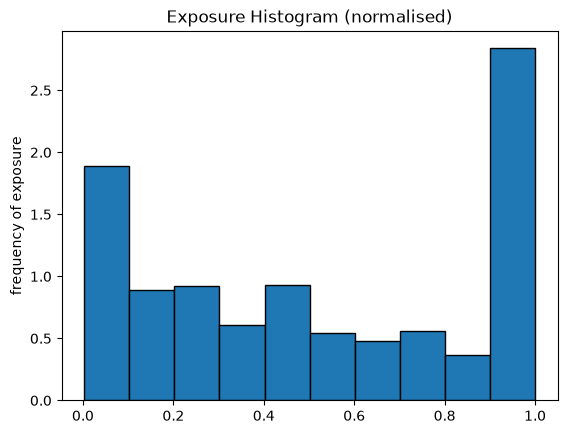

In [44]:
#Plot of the histogram of exposure
plt.hist(policies["Exposure"],density=True,edgecolor="black", linewidth=1)
plt.title("Exposure Histogram (normalised)")
plt.ylabel("frequency of exposure")
plt.show()

### 3.6 Apply the cleaning and check it


In [40]:
# 1. Drop the claims without a policy.
claims = claims[claims["IDpol"].isin(policies["IDpol"])].copy()
# 2. Rebuild ClaimNb from the claims table.

if "n_claim_rows" in policies.columns: #Avoid errors if the cell is rerun after dropping the column
    policies["ClaimNb"] = policies["n_claim_rows"]
    policies = policies.drop(columns="n_claim_rows")
# 3. Drop the policies with more than 5 claims, and their claims.
too_many = policies.loc[policies["ClaimNb"] > 5, "IDpol"]
policies = policies[~policies["IDpol"].isin(too_many)].reset_index(drop=True)
claims = claims[~claims["IDpol"].isin(too_many)].reset_index(drop=True)
# 4. Cap exposure at one year.
policies["Exposure"] = policies["Exposure"].clip(upper=1.0)
# Total claim cost of each policy (0 without claims).
policies["ClaimAmount"] = policies["IDpol"].map(claims.groupby("IDpol")["ClaimAmount"].sum()).fillna(0.0)
# Consistency checks.
assert policies["ClaimNb"].sum() == len(claims)
assert np.isclose(policies["ClaimAmount"].sum(), claims["ClaimAmount"].sum())
print(f"clean data: {len(policies):,} policies, {len(claims):,} claims, "
      f"frequency {policies['ClaimNb'].sum() / policies['Exposure'].sum():.4f} claims per year")

clean data: 678,007 policies, 26,383 claims, frequency 0.0736 claims per year


Wüthrich & Merz (2023, §13.1) report "26,383 claims on 678,007 insurance policies" after the same steps: **our counts match exactly.**

## 4. EDA

### 4.1 Claim frequency by risk factor

We plot the observed frequency (claims / exposure) by band of each variable as a red segmented line, with the exposure of each band as gray bars.

In [13]:
policies.Density.describe()

count    678007.000000
mean       1792.430975
std        3958.663031
min           1.000000
25%          92.000000
50%         393.000000
75%        1658.000000
max       27000.000000
Name: Density, dtype: float64

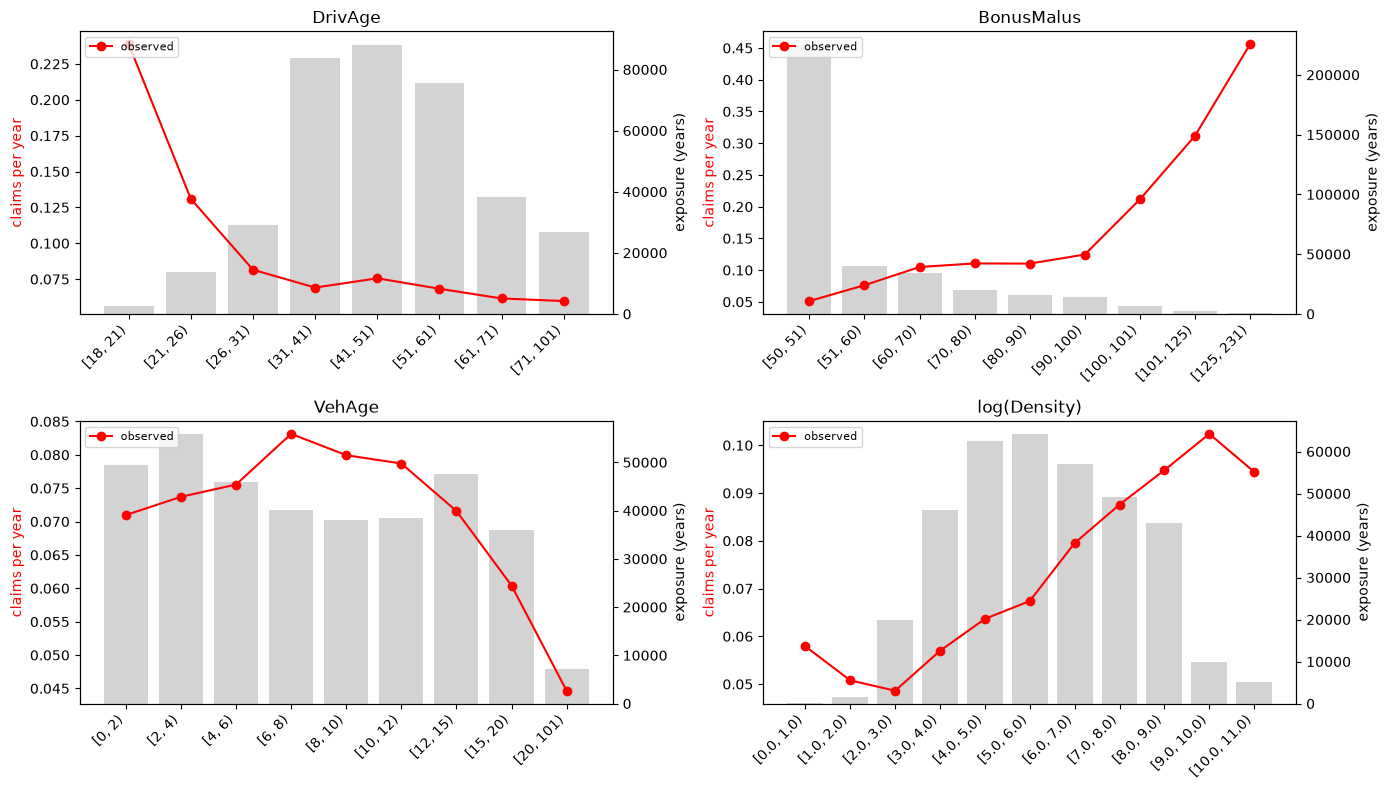

In [14]:
def one_way(df: pd.DataFrame, by: pd.Series, ax, pred_cols=()):
    """Observed (and optionally predicted) claim frequency by group, with the exposure of each group as bars."""
    g = df.assign(group=by).groupby("group", observed=True)
    exposure = g["Exposure"].sum()
    x = np.arange(len(exposure))
    ax_bars = ax.twinx()
    ax_bars.bar(x, exposure, color="lightgrey")
    ax_bars.set_ylabel("exposure (years)")
    ax.set_zorder(ax_bars.get_zorder() + 1)
    ax.patch.set_visible(False)
    ax.plot(x, g["ClaimNb"].sum() / exposure, "o-", color="red", label="observed")
    for col in pred_cols:  # predicted frequency, averaged with exposure weights
        ax.plot(x, g.apply(lambda d: np.average(d[col], weights=d["Exposure"]), include_groups=False), "s--", label=col)
    ax.set_xticks(x, [str(v) for v in exposure.index], rotation=45, ha="right")
    ax.set_ylabel("claims per year", color="red")
    ax.legend(loc="upper left", fontsize=8)


fig, axes = plt.subplots(2, 2, figsize=(14, 8))
one_way(policies, pd.cut(policies["DrivAge"], [18, 21, 26, 31, 41, 51, 61, 71, 101], right=False), axes[0, 0])
axes[0, 0].set_title("DrivAge")
one_way(policies, pd.cut(policies["BonusMalus"], [50, 51, 60, 70, 80, 90, 100, 101, 125, 231], right=False), axes[0, 1])
axes[0, 1].set_title("BonusMalus")
one_way(policies, pd.cut(policies["VehAge"], [0, 2, 4, 6, 8, 10, 12, 15, 20, 101], right=False), axes[1, 0])
axes[1, 0].set_title("VehAge")
one_way(policies, pd.cut(np.log(policies["Density"]), np.arange(0, 11.5, 1.0), right=False), axes[1, 1])
axes[1, 1].set_title("log(Density)")
fig.tight_layout()
plt.show()

- **BonusMalus** is the strongest factor: from 0.05 claims per year at 50 (maximum bonus) to above 0.4 beyond 125.
- **Young drivers** claim much more often: about 0.24 per year below 21, against about 0.07 after 30.
- Frequency grows with **density** (cities) and falls for **old cars**.
- `Area` is not shown: it is just `Density` cut into six classes (checked below), so the models use `Density` only.

In [15]:
policies.groupby("Area", observed=True)["Density"].agg(["min", "max"])

,min,max
Area,,
A,1,50
B,50,100
C,100,500
D,500,1993
E,2001,9850
F,10008,27000


### 4.2 Claim amounts

We investigate the statistics on the amounts of claims. Since they span multiple orders of magnitude, we plot the results with a logarithmic scale (base 10).

QUANTILES OF CLAIMS
 Quantiles   Values
     0.500   1172.0
     0.900   2759.0
     0.990  16560.0
     0.999 152238.0
Largest claim: 4,075,401
Share of the total cost in the largest 1% of claims: 38%
Most frequent amounts: {1204.0: 4792, 1128.12: 3056, 1172.0: 2071}


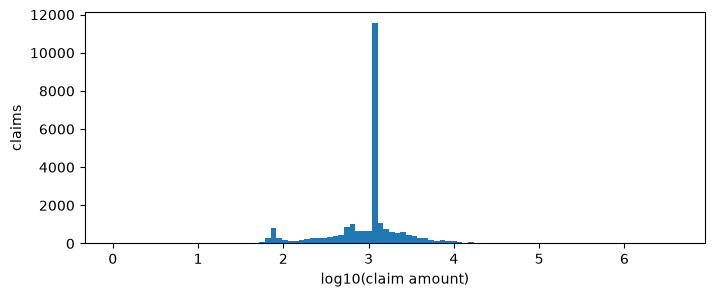

In [16]:
amount = claims["ClaimAmount"]
print("QUANTILES OF CLAIMS")
q = amount.quantile([0.5, 0.9, 0.99, 0.999]).round(0)
print(q.rename_axis("Quantiles").reset_index(name="Values").to_string(index=False))
print(f"Largest claim: {amount.max():,.0f}")
print(f"Share of the total cost in the largest 1% of claims: {amount[amount >= amount.quantile(0.99)].sum() / amount.sum():.0%}")
print(f"Most frequent amounts: {amount.value_counts().head(3).to_dict()}")

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(np.log10(amount), bins=100)
ax.set_xlabel("log10(claim amount)")
ax.set_ylabel("claims")
plt.show()

Two features of the claim amounts shape the severity model:

- **A heavy tail.** The median claim costs about 1,200, but the largest 1% of claims make up 38% of the total cost, and the largest one is 4 million.
- **Fixed amounts.** Thousands of claims cost exactly 1,204, 1,128.12 or 1,172 (the spike in the histogram). They are most likely flat amounts settled between French insurers for small material damage, not measured costs.

## 5. Train/test split

We keep 20% of the policies aside as a **test set**, used only at the end to compare the models.

One detail matters here. 38% of the policies share all their characteristics with another record (the same car renewed during the year, fleets of identical cars). If two records of the same car end up one in train and one in test, the test result is optimistic. So the split is made **by group**: all policies with the same characteristics go to the same side. Otherwise, the models would predict on data potentially aready obseved during training, introducing leakage in the model.

In [17]:
cov = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand", "VehGas", "Area", "Density", "Region"]

#We group policies whose covariates are identical
gsize = policies.groupby(cov, observed=True)["IDpol"].transform("size")  # size of each row's group

#We check wether the same combination of covariates is bserved in more than one policy
print(f"The percentage of fatures cmbinations which appear in more than one policy is: {(gsize > 1).mean():.1%}")


The percentage of fatures cmbinations which appear in more than one policy is: 38.0%


In [18]:
COVARIATES = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand", "VehGas", "Area", "Density", "Region"]


def grouped_split(df: pd.DataFrame, share: float, seed: int) -> np.ndarray:
    """True for the rows sent to the second set. Rows with identical covariates ALWAYS stay together, in the same split."""
    group = df.groupby(COVARIATES, observed=True, sort=False).ngroup().to_numpy()
    draws = np.random.default_rng(seed).random(group.max() + 1)  # one draw per group
    return draws[group] < share


policies["test"] = grouped_split(policies, 0.2, SEED)
claims["test"] = claims["IDpol"].map(policies.set_index("IDpol")["test"])
train, test = policies[~policies["test"]].reset_index(drop=True), policies[policies["test"]].reset_index(drop=True)

for name, df in [("train", train), ("test", test)]:
    print(f"{name}: {len(df):,} policies, {df['ClaimNb'].sum():,} claims, frequency {df['ClaimNb'].sum() / df['Exposure'].sum():.4f}")

train: 542,239 policies, 21,111 claims, frequency 0.0737
test: 135,768 policies, 5,272 claims, frequency 0.0735


## 6. Frequency model

We recall that the main formula to bear in mind is: **Pure premium = frequency x severity**. We estimate the two factors in different ways, to assess which combination of ML techniques give better results.

The target is the number of claims $N$ of a policy observed for $e$ years (in this case $e$ will be a number between 0 and 1). All models predict a **frequency** $\lambda(x)$, in claims per year, and assume $N \sim \text{Poisson}(\lambda(x)\, e)$: the exposure enters as a moltiplicative factor of the frequency (in ML terms this is an *offset*, see the README).

Three measures are used in the following:
- **Poisson deviance**: how close the predictions are to the observed counts (lower is better);
- **Gini index**: how well the model ranks policies from low to high risk (higher is better, 0 = no ranking);
- **Balance**: total predicted / total observed claims (should be 1).

The precise definition of the three measures can be found in the README (CHECK e aggiungi nel caso)

In [19]:
def lorenz_curve(y_rate, pred, exposure):
    """Cumulative share of exposure and of observed losses, policies sorted from low to high prediction.
    Policies with equal predictions are merged into one step, so ties do not depend on the row order."""
    _, group = np.unique(pred, return_inverse=True)
    exposure_sum = np.bincount(group, weights=exposure)
    loss_sum = np.bincount(group, weights=y_rate * exposure)
    return (np.concatenate([[0], np.cumsum(exposure_sum)]) / exposure_sum.sum(),
            np.concatenate([[0], np.cumsum(loss_sum)]) / loss_sum.sum())


def gini(y_rate, pred, exposure):
    """Gini index = 1 - 2 x area under the Lorenz curve."""
    x, y = lorenz_curve(y_rate, pred, exposure)
    return 1 - 2 * np.trapezoid(y, x)


def frequency_scores(df, pred):
    y, e = df["ClaimNb"] / df["Exposure"], df["Exposure"]
    return {"Poisson deviance": mean_poisson_deviance(y, pred, sample_weight=e),
            "Gini": gini(y.to_numpy(), pred, e.to_numpy()),
            "balance": (pred * e).sum() / df["ClaimNb"].sum()}

### 6.1 Baseline: the same frequency for everybody

In [20]:
base_frequency = train["ClaimNb"].sum() / train["Exposure"].sum()
freq_pred = {"homogeneous": (np.full(len(train), base_frequency), np.full(len(test), base_frequency))}
print(f"homogeneous frequency: {base_frequency:.4f} claims per year")

homogeneous frequency: 0.0737 claims per year


### 6.2 Poisson GLM

A GLM needs the effects written by hand. From the plots of §4.1: age bands for driver and car, `BonusMalus` linear on the log scale plus an indicator for the maximum bonus (50), $\log(\text{Density})$, and brand, fuel and region as categories. For each categorical variable, the level with the most exposure is the **reference**: its relativity is 1, and every other level is measured against it.

In [21]:
DRIVAGE_BANDS = [18, 21, 26, 31, 41, 51, 71, 101]
VEHAGE_BANDS = [0, 6, 12, 16, 21, 101]


def glm_features(df: pd.DataFrame) -> pd.DataFrame:
    """Bands, caps and transformations of the raw covariates, chosen from the one-way plots."""
    X = pd.DataFrame(index=df.index)
    X["DrivAge"] = pd.cut(df["DrivAge"], DRIVAGE_BANDS, right=False).astype(str)
    X["VehAge"] = pd.cut(df["VehAge"], VEHAGE_BANDS, right=False).astype(str)
    X["VehPower"] = df["VehPower"].clip(upper=9).astype(str)  # 9 = "9 or more"
    X["VehBrand"] = df["VehBrand"].astype(str)
    X["VehGas"] = df["VehGas"].astype(str)
    X["Region"] = df["Region"].astype(str)
    X["BonusMalus"] = df["BonusMalus"].clip(upper=150)  # only 209 policies above 150
    X["MaxBonus"] = (df["BonusMalus"] == 50).astype(float)  # the floor of the scale, where most drivers sit
    X["LogDensity"] = np.log(df["Density"])
    return X


def design_matrix(X: pd.DataFrame, levels: dict) -> pd.DataFrame:
    """Intercept, numeric columns, then one 0/1 column per non-reference level ("DrivAge=[18, 21)").
    `levels` gives, for each categorical column, its levels with the reference first."""
    parts = [pd.Series(1.0, index=X.index, name="Intercept"), X.drop(columns=list(levels)).astype(float)]
    for col, col_levels in levels.items():
        cat = pd.Series(pd.Categorical(X[col], categories=col_levels), index=X.index)
        parts.append(pd.get_dummies(cat, prefix=col, prefix_sep="=", drop_first=True, dtype=float))
    return pd.concat(parts, axis=1)


def reference_first(X: pd.DataFrame, weight: pd.Series, columns: list) -> dict:
    """For each categorical column, all its levels with the one carrying the most weight first."""
    levels = {}
    for col in columns:
        w = weight.groupby(X[col]).sum().sort_values(ascending=False)
        levels[col] = list(w.index)
    return levels


X_train, X_test = glm_features(train), glm_features(test)
FREQ_LEVELS = reference_first(X_train, train["Exposure"], ["DrivAge", "VehAge", "VehPower", "VehBrand", "VehGas", "Region"])
D_train, D_test = design_matrix(X_train, FREQ_LEVELS), design_matrix(X_test, FREQ_LEVELS)

# Newton's method: same estimates as the default algorithm, less memory on 540k rows.
freq_glm = sm.GLM(train["ClaimNb"], D_train, family=sm.families.Poisson(), offset=np.log(train["Exposure"])).fit(method="newton")
freq_pred["GLM"] = (np.asarray(freq_glm.predict(D_train, offset=np.zeros(len(D_train)))),  # offset 0 = one year
                    np.asarray(freq_glm.predict(D_test, offset=np.zeros(len(D_test)))))

print(f"{D_train.shape[1]} parameters; predicted / observed claims on train: {freq_glm.fittedvalues.sum() / train['ClaimNb'].sum():.6f}")

51 parameters; predicted / observed claims on train: 1.000000


The GLM reproduces the total number of training claims **exactly**: a property of the Poisson GLM with log link and intercept (README). Its coefficients read as **relativities**, multiplicative effects on the frequency:

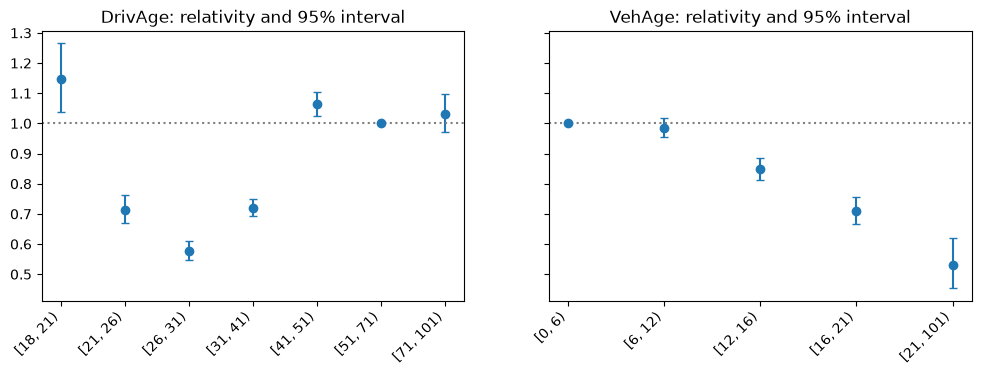

BonusMalus: +10 points multiply the frequency by 1.23
MaxBonus:   drivers at 50 claim 0.65 times what the straight line predicts
Density:    a town twice as dense multiplies the frequency by 1.05


In [22]:
relativity = np.exp(freq_glm.params)
low, high = np.exp(freq_glm.conf_int()[0]), np.exp(freq_glm.conf_int()[1])

fig, axes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for ax, factor in zip(axes, ["DrivAge", "VehAge"]):
    order = sorted(FREQ_LEVELS[factor], key=lambda s: float(s.split(",")[0][1:]))  # bands in age order
    names = [f"{factor}={lv}" for lv in order]
    r = [relativity.get(n, 1.0) for n in names]  # the reference level has no parameter: relativity 1
    err = [[r_i - low.get(n, 1.0) for r_i, n in zip(r, names)], [high.get(n, 1.0) - r_i for r_i, n in zip(r, names)]]
    ax.errorbar(range(len(order)), r, yerr=err, fmt="o", capsize=3)
    ax.axhline(1, color="grey", linestyle=":")
    ax.set_xticks(range(len(order)), order, rotation=45, ha="right")
    ax.set_title(f"{factor}: relativity and 95% interval")
plt.show()

print(f"BonusMalus: +10 points multiply the frequency by {np.exp(10 * freq_glm.params['BonusMalus']):.2f}")
print(f"MaxBonus:   drivers at 50 claim {np.exp(freq_glm.params['MaxBonus']):.2f} times what the straight line predicts")
print(f"Density:    a town twice as dense multiplies the frequency by {2 ** freq_glm.params['LogDensity']:.2f}")

The age effect looks very different from the raw plot of §4.1: the youngest drivers are only 15–20% above the reference, and drivers aged 21–40 are even below it. Young drivers also start with a high `BonusMalus` (100), and the GLM attributes most of their risk to it. Raw plots show *marginal* effects, the GLM *conditional* ones.

### 6.3 Gradient boosting (LightGBM)

LightGBM builds hundreds of small decision trees, each correcting the errors of the previous ones, and finds the shapes and interactions by itself: it uses the raw covariates. It is told the exposure through `init_score`: the starting prediction of each policy is $\log e + \log \hat\lambda_{\text{homogeneous}}$, and the trees learn a multiplicative correction to it. Early stopping on a validation part of the training set (again grouped) picks the number of trees.

In [23]:
GBM_FEATURES = ["VehPower", "VehAge", "DrivAge", "BonusMalus", "VehBrand", "VehGas", "Density", "Region"]
GBM_PARAMS = {"objective": "poisson", "learning_rate": 0.05, "num_leaves": 31, "min_data_in_leaf": 500,
              "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 1.0,
              "verbose": -1, "seed": SEED, "deterministic": True, "force_row_wise": True}


def gbm_dataset(df, reference=None):
    """Claim counts as label; log(exposure) + log(homogeneous frequency) as starting point."""
    return lgb.Dataset(df[GBM_FEATURES], label=df["ClaimNb"], reference=reference,
                       init_score=np.log(df["Exposure"]) + np.log(base_frequency))


# Choose the number of trees on a validation part of the training set...
is_val = grouped_split(train, 0.2, SEED + 1)
fit_part, val_part = train[~is_val], train[is_val]
d_fit = gbm_dataset(fit_part)
booster = lgb.train(GBM_PARAMS, d_fit, num_boost_round=3000, valid_sets=[gbm_dataset(val_part, reference=d_fit)],
                    callbacks=[lgb.early_stopping(100, verbose=False)])
n_trees = booster.best_iteration

# ...then refit on the whole training set with that number of trees.
freq_gbm = lgb.train(GBM_PARAMS, gbm_dataset(train), num_boost_round=n_trees)
# predict() returns only the sum of the trees, without init_score: the base frequency must be put back.
freq_pred["GBM"] = (base_frequency * np.exp(freq_gbm.predict(train[GBM_FEATURES], raw_score=True)),
                    base_frequency * np.exp(freq_gbm.predict(test[GBM_FEATURES], raw_score=True)))
print(f"trees: {n_trees}")

trees: 325


### 6.4 Comparison on the test set

In [24]:
pd.DataFrame({name: frequency_scores(test, pred_test) for name, (_, pred_test) in freq_pred.items()}).T.round(4) + 0.0

,Poisson deviance,Gini,balance
homogeneous,0.4767,0.0000,1.0027
GLM,0.4543,0.2976,1.0006
GBM,0.4457,0.3307,1.0010


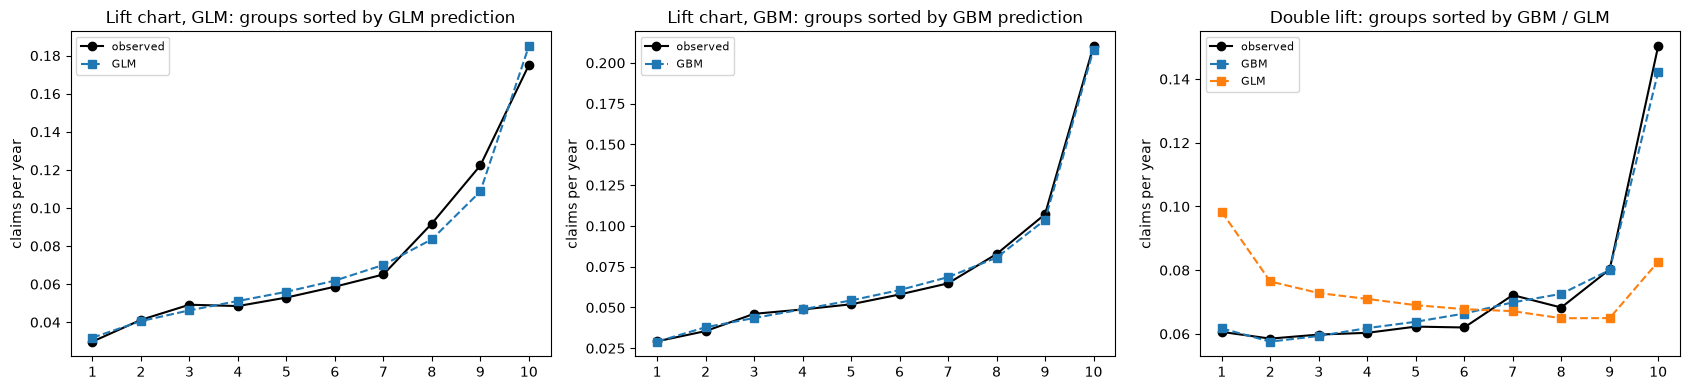

In [25]:
def lift_chart(y_rate, preds: dict, exposure, ax, n_bins=10, sort_by=None):
    """Policies sorted by `sort_by` and cut into n_bins groups of equal exposure:
    observed and predicted frequency (exposure-weighted) in each group."""
    order = np.argsort(sort_by, kind="stable")
    bins = np.minimum((np.cumsum(exposure[order]) / exposure.sum() * n_bins).astype(int), n_bins - 1)
    def by_bin(values):
        return np.bincount(bins, weights=values[order] * exposure[order]) / np.bincount(bins, weights=exposure[order])
    x = np.arange(1, n_bins + 1)
    ax.plot(x, by_bin(y_rate), "o-", color="black", label="observed")
    for name, pred in preds.items():
        ax.plot(x, by_bin(pred), "s--", label=name)
    ax.set_xticks(x)
    ax.set_ylabel("claims per year")
    ax.legend(fontsize=8)


y_test = (test["ClaimNb"] / test["Exposure"]).to_numpy()
e_test = test["Exposure"].to_numpy()
glm_test, gbm_test = freq_pred["GLM"][1], freq_pred["GBM"][1]

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
lift_chart(y_test, {"GLM": glm_test}, e_test, axes[0], sort_by=glm_test)
axes[0].set_title("Lift chart, GLM: groups sorted by GLM prediction")
lift_chart(y_test, {"GBM": gbm_test}, e_test, axes[1], sort_by=gbm_test)
axes[1].set_title("Lift chart, GBM: groups sorted by GBM prediction")
lift_chart(y_test, {"GBM": gbm_test, "GLM": glm_test}, e_test, axes[2], sort_by=gbm_test / glm_test)
axes[2].set_title("Double lift: groups sorted by GBM / GLM")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "frequency_test.png", dpi=110)
plt.show()

- **Lift charts**: both models are calibrated across risk groups (observed ≈ predicted in each group); the GBM separates risks more, with a higher last group.
- **Double lift**: on the left are the policies for which the GBM predicts much less than the GLM, on the right much more. In both places the observed frequency follows the GBM: where the two models disagree, the GBM is right.

Where does the GLM go wrong? The clearest place is `BonusMalus`:

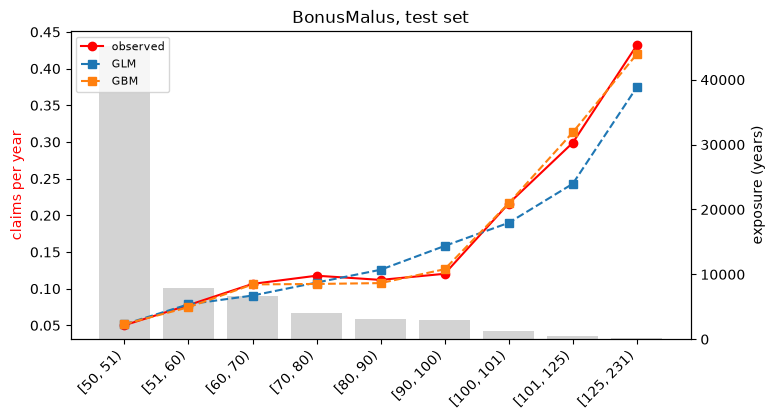

In [26]:
test_plot = test.assign(GLM=glm_test, GBM=gbm_test)
fig, ax = plt.subplots(figsize=(8, 4))
one_way(test_plot, pd.cut(test_plot["BonusMalus"], [50, 51, 60, 70, 80, 90, 100, 101, 125, 231], right=False), ax, pred_cols=["GLM", "GBM"])
ax.set_title("BonusMalus, test set")
plt.show()

The GLM's straight line (on the log scale) over-predicts between 80 and 100 and under-predicts above 100, where the frequency jumps; the GBM follows the data.

## 7. Severity model

The target is the cost of one claim, modelled on the claims only (one row per claim). We use a **Gamma GLM** with log link: amounts are positive and skewed, and their spread grows with their mean.

### 7.1 Large claims

A handful of claims would dominate any model fitted on raw amounts. How much of the training cost sits above a few thresholds?

In [27]:
train_claims = claims[~claims["test"]].reset_index(drop=True)
test_claims = claims[claims["test"]].reset_index(drop=True)

rows = []
for u in [20_000, 50_000, 100_000, 200_000]:
    above = (train_claims["ClaimAmount"] - u).clip(lower=0)
    rows.append({"threshold": u, "claims above": int((train_claims["ClaimAmount"] > u).sum()),
                 "share of cost above": above.sum() / train_claims["ClaimAmount"].sum()})
pd.DataFrame(rows).round(3)

,threshold,claims above,share of cost above
0,20000,175,0.311
1,50000,72,0.244
2,100000,32,0.195
3,200000,15,0.149


**Decision:** claims are capped at 50,000. The severity model learns from capped amounts, where the covariates can explain something; the cost above the cap is added back to everybody as a **loading** $L$, so that nothing is lost:

$$\text{expected cost per claim} = \text{capped severity} \times (1 + L), \qquad L = \frac{\text{total cost above 50,000}}{\text{total capped cost}} \ \text{(on train)}.$$

In [28]:
CAP = 50_000
for df in (train_claims, test_claims):
    df["Capped"] = df["ClaimAmount"].clip(upper=CAP)
LOADING = (train_claims["ClaimAmount"] - CAP).clip(lower=0).sum() / train_claims["Capped"].sum()
print(f"{(train_claims['ClaimAmount'] > CAP).sum()} training claims above {CAP:,}; loading L = {LOADING:.3f}")

72 training claims above 50,000; loading L = 0.322


### 7.2 Gamma GLM

Same features as the frequency GLM, without region and brand: with about 21,000 claims instead of 540,000 policies, we keep the model small, and those two variables alone would add about 30 parameters.

In [29]:
SEV_LEVELS_COLUMNS = ["DrivAge", "VehAge", "VehPower", "VehGas"]


def severity_design(df, levels):
    return design_matrix(glm_features(df).drop(columns=["VehBrand", "Region"]), levels)


claim_covariates = policies.set_index("IDpol")[GBM_FEATURES]
train_claims = train_claims.join(claim_covariates, on="IDpol")
test_claims = test_claims.join(claim_covariates, on="IDpol")

SEV_LEVELS = reference_first(glm_features(train_claims), pd.Series(1.0, index=train_claims.index), SEV_LEVELS_COLUMNS)
sev_glm = sm.GLM(train_claims["Capped"], severity_design(train_claims, SEV_LEVELS),
                 family=sm.families.Gamma(sm.families.links.Log())).fit()

summary = pd.DataFrame({"relativity": np.exp(sev_glm.params), "p-value": sev_glm.pvalues}).drop(index="Intercept")
print(f"dispersion: {sev_glm.scale:.1f}, i.e. a coefficient of variation of about {np.sqrt(sev_glm.scale):.1f} per claim")
summary[summary["p-value"] < 0.05].round(3)

dispersion: 5.0, i.e. a coefficient of variation of about 2.2 per claim


,relativity,p-value
BonusMalus,1.003,0.029
"DrivAge=[71, 101)",1.181,0.015
"DrivAge=[18, 21)",1.368,0.005
"VehAge=[6, 12)",0.898,0.002
"VehAge=[12, 16)",0.894,0.014
VehPower=5,0.909,0.045


Only a few effects are clearly different from 1 (above: those with p-value below 5%), and the dispersion is large: given who drives and which car, the cost of a claim is mostly noise. This makes sense: the covariates describe the driver and the car, not the accident.

### 7.3 Is there more to find? Cross-validation

Could a GBM find what the GLM misses? With a small and noisy target, a single validation split can be misleading, so we compare the mean, the GLM and a small GBM with **5-fold cross-validation** on the training claims (grouped like the split). Metric: $D^2$, the share of the Gamma deviance of the mean that a model removes (0 = no better than the mean).

In [30]:
SEV_GBM_PARAMS = {"objective": "gamma", "learning_rate": 0.02, "num_leaves": 7, "min_data_in_leaf": 300,
                  "feature_fraction": 0.8, "bagging_fraction": 0.8, "bagging_freq": 1, "lambda_l2": 10.0,
                  "verbose": -1, "seed": SEED, "deterministic": True, "force_row_wise": True}

group = train_claims.groupby(GBM_FEATURES, observed=True, sort=False).ngroup().to_numpy()
fold = np.random.default_rng(SEED).integers(0, 5, group.max() + 1)[group]
d2 = {"GLM": [], "GBM": []}
for k in range(5):
    inner, outer = train_claims[fold != k], train_claims[fold == k]
    mean = inner["Capped"].mean()
    deviance_of_mean = mean_gamma_deviance(outer["Capped"], np.full(len(outer), mean))
    # GLM
    levels = reference_first(glm_features(inner), pd.Series(1.0, index=inner.index), SEV_LEVELS_COLUMNS)
    glm_k = sm.GLM(inner["Capped"], severity_design(inner, levels), family=sm.families.Gamma(sm.families.links.Log())).fit()
    d2["GLM"].append(1 - mean_gamma_deviance(outer["Capped"], glm_k.predict(severity_design(outer, levels))) / deviance_of_mean)
    # GBM, starting from the mean
    gbm_k = lgb.train(SEV_GBM_PARAMS, lgb.Dataset(inner[GBM_FEATURES], label=inner["Capped"],
                                                  init_score=np.full(len(inner), np.log(mean))), num_boost_round=300)
    pred = mean * np.exp(gbm_k.predict(outer[GBM_FEATURES], raw_score=True))
    d2["GBM"].append(1 - mean_gamma_deviance(outer["Capped"], pred) / deviance_of_mean)

cv = pd.DataFrame(d2, index=[f"fold {k + 1}" for k in range(5)]).T
cv["mean"] = cv.mean(axis=1)
cv.round(4)

,fold 1,fold 2,fold 3,fold 4,fold 5,mean
GLM,-0.0018,0.0009,0.0051,0.0032,-0.0002,0.0015
GBM,0.0021,-0.0109,0.0104,0.0043,-0.0115,-0.0011


Neither model removes more than a fraction of a percent of the deviance, and the folds disagree even on the sign: **the covariates carry very little information on the cost of a claim**, and a flexible model mostly fits noise. We keep the GLM, which is simple and explainable. On the test claims:

In [31]:
sev_test = sev_glm.predict(severity_design(test_claims, SEV_LEVELS))
d2_test = 1 - mean_gamma_deviance(test_claims["Capped"], sev_test) / mean_gamma_deviance(
    test_claims["Capped"], np.full(len(test_claims), train_claims["Capped"].mean()))
print(f"Gamma GLM, test claims: D2 = {d2_test:.4f}")

Gamma GLM, test claims: D2 = 0.0066


## 8. Pure premium

Pure premium per year = frequency × expected cost per claim. We combine each frequency model with the severity GLM (which predicts a severity for **every** policy, with or without claims), and compare with the homogeneous model.

Before comparing, each model is rescaled by a constant so that its total predicted cost equals the total observed cost **on the training set** (balance correction). The test set stays untouched, as next year's portfolio would be.

In [32]:
sev_all = {name: np.asarray(sev_glm.predict(severity_design(df, SEV_LEVELS))) * (1 + LOADING) for name, df in [("train", train), ("test", test)]}
mean_severity = train_claims["Capped"].mean() * (1 + LOADING)

pp = {  # (train, test) predictions, cost per year of exposure
    "homogeneous": (freq_pred["homogeneous"][0] * mean_severity, freq_pred["homogeneous"][1] * mean_severity),
    "GLM x GLM": (freq_pred["GLM"][0] * sev_all["train"], freq_pred["GLM"][1] * sev_all["test"]),
    "GBM x GLM": (freq_pred["GBM"][0] * sev_all["train"], freq_pred["GBM"][1] * sev_all["test"]),
}

# Balance correction on the training set only.
for name, (p_train, p_test) in pp.items():
    factor = train["ClaimAmount"].sum() / (p_train * train["Exposure"]).sum()
    pp[name] = (p_train * factor, p_test * factor)
    print(f"{name:12s} correction factor {factor:.4f}")

homogeneous  correction factor 1.0000
GLM x GLM    correction factor 1.0000
GBM x GLM    correction factor 1.0005


In [33]:
y_cost = (test["ClaimAmount"] / test["Exposure"]).to_numpy()  # observed cost per year, uncapped


def pure_premium_scores(pred):
    return {"Tweedie deviance (p=1.9)": mean_tweedie_deviance(y_cost, pred, sample_weight=e_test, power=1.9),
            "Gini": gini(y_cost, pred, e_test),
            "balance": (pred * e_test).sum() / test["ClaimAmount"].sum()}


results = pd.DataFrame({name: pure_premium_scores(p_test) for name, (_, p_test) in pp.items()}).T
results.round(4) + 0.0

,Tweedie deviance (p=1.9),Gini,balance
homogeneous,34.5296,0.0000,1.1325
GLM x GLM,34.0331,0.3002,1.1294
GBM x GLM,33.9689,0.3150,1.1303


- **Both models rank risks far better than the homogeneous premium** (Gini about 0.30 against 0), and the GBM frequency adds a little on top of the GLM.
- **Every model over-predicts the test cost by about 13%**, the homogeneous one included. This is not a modelling error but the large-claim loading: the test set happens to contain fewer very large claims than the training set. With a heavy tail, the cost of one portfolio in one year is very uncertain.
- The differences between the two models are small compared with this uncertainty: before choosing between them for a real tariff, a bootstrap of the test set or several years of data would be needed.

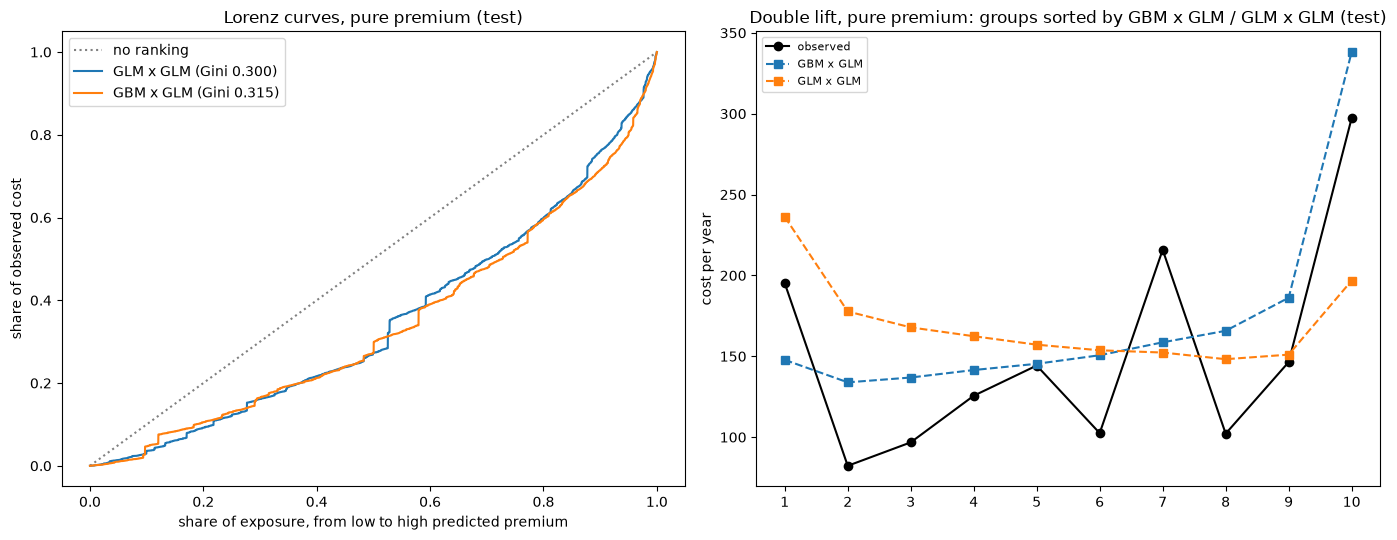

In [34]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
ax = axes[0]
ax.plot([0, 1], [0, 1], ":", color="grey", label="no ranking")
for name in ["GLM x GLM", "GBM x GLM"]:
    x, y = lorenz_curve(y_cost, pp[name][1], e_test)
    ax.plot(x, y, label=f"{name} (Gini {gini(y_cost, pp[name][1], e_test):.3f})")
ax.set_xlabel("share of exposure, from low to high predicted premium")
ax.set_ylabel("share of observed cost")
ax.set_title("Lorenz curves, pure premium (test)")
ax.legend()

lift_chart(y_cost, {"GBM x GLM": pp["GBM x GLM"][1], "GLM x GLM": pp["GLM x GLM"][1]}, e_test, axes[1],
           sort_by=pp["GBM x GLM"][1] / pp["GLM x GLM"][1])
axes[1].set_ylabel("cost per year")
axes[1].set_title("Double lift, pure premium: groups sorted by GBM x GLM / GLM x GLM (test)")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "pure_premium_test.png", dpi=110)
plt.show()

The Lorenz curves confirm the ranking: the GBM-based premium puts slightly more of the observed cost on the policies it rates highest. The double lift, instead, is noisy: in each group a few large claims decide the observed cost. The cost of a claim is so unpredictable that the frequency is the part of the pure premium where models can be compared reliably.

## 9. Do the models work?

Sections 6–8 compared models with each other. Here the question is absolute: on the test set, which no model has seen, do the predictions **separate the risks** and do they have the **right level**? We cut the test policies into 10 groups of equal exposure, from the lowest to the highest prediction, and compare observed and predicted values in each group.

In [35]:
def group_table(y_rate, pred, exposure, n_groups=10):
    """Observed and predicted (exposure-weighted) means in n_groups groups of equal exposure, sorted by prediction."""
    order = np.argsort(pred, kind="stable")
    group = np.minimum((np.cumsum(exposure[order]) / exposure.sum() * n_groups).astype(int), n_groups - 1)
    w = np.bincount(group, weights=exposure[order])
    observed = np.bincount(group, weights=y_rate[order] * exposure[order]) / w
    predicted = np.bincount(group, weights=pred[order] * exposure[order]) / w
    return pd.DataFrame({"observed": observed, "predicted": predicted, "predicted / observed": predicted / observed},
                        index=pd.RangeIndex(1, n_groups + 1, name="group"))


def summary(table, total_predicted, total_observed):
    """Riskiest vs safest group, worst group error, and total level."""
    return {"observed, safest group": table["observed"].iloc[0],
            "observed, riskiest group": table["observed"].iloc[-1],
            "riskiest / safest": table["observed"].iloc[-1] / table["observed"].iloc[0],
            "largest group error": (table["predicted / observed"] - 1).abs().max(),
            "total predicted / observed": total_predicted / total_observed}


checks = {}
# Frequency: claims per year.
for name in ["GLM", "GBM"]:
    pred = freq_pred[name][1]
    checks[f"frequency, {name}"] = summary(group_table(y_test, pred, e_test), (pred * e_test).sum(), test["ClaimNb"].sum())

# Pure premium on the predictable part of the cost: claims capped at 50,000, loading removed.
capped_cost = test["IDpol"].map(test_claims.groupby("IDpol")["Capped"].sum()).fillna(0.0).to_numpy()
for name in ["GLM x GLM", "GBM x GLM"]:
    pred = pp[name][1] / (1 + LOADING)
    checks[f"pure premium (capped), {name}"] = summary(group_table(capped_cost / e_test, pred, e_test),
                                                       (pred * e_test).sum(), capped_cost.sum())
pd.DataFrame(checks).T.round(3)

,"observed, safest group","observed, riskiest group",riskiest / safest,largest group error,total predicted / observed
"frequency, GLM",0.030,0.175,5.868,0.112,1.001
"frequency, GBM",0.029,0.210,7.185,0.066,1.001
"pure premium (capped), GLM x GLM",50.942,330.464,6.487,0.141,1.001
"pure premium (capped), GBM x GLM",45.390,396.944,8.745,0.139,1.002


In [36]:
# Severity: the same check on the test claims (capped amounts, one weight per claim), with 5 groups.
group_table(test_claims["Capped"].to_numpy(), np.asarray(sev_test), np.ones(len(test_claims)), n_groups=5).round(2)

,observed,predicted,predicted / observed
group,,,
1,1591.18,1534.38,0.96
2,1857.68,1642.12,0.88
3,1549.31,1731.00,1.12
4,1770.43,1821.00,1.03
5,1988.16,2041.69,1.03


- **Frequency: yes.** The 10% of policies the GBM rates riskiest have about 7 times the claim frequency of the 10% it rates safest (0.21 against 0.03 claims per year), the GLM about 6 times; in every group the prediction is within 7% of what happened (GLM: 11%), and the totals agree within 0.1%.
- **Severity: hardly.** The predicted cost per claim moves little (the 5 groups range from about 1,550 to 2,050), and the observed averages do not climb steadily with it. The model is close to the average cost with small adjustments, which is what the cross-validation of §7.3 said. For the pure premium this is enough, because what matters is the mean, and the mean is right.
- **Pure premium, predictable part: yes.** On the cost below 50,000 per claim, the predicted total is within 0.2% of the observed one; the riskiest 10% of policies cost 6.5 (GLM × GLM) to almost 9 (GBM × GLM) times the safest 10%, and every group is within 14%.
- **The very large claims are not predictable** by any of these models. The loading covers them on average over the training years, but a single test year can have more or fewer of them: here fewer, hence the 13% over-prediction of §8 on the full cost.

## 10. Conclusions

- **Check the data before modelling.** For 9,139 policies the raw claim counts are wrong; rebuilding them from the claims table and removing a few anomalous records reproduces exactly the counts published by Wüthrich & Merz (2023).
- **Frequency: the GBM beats the GLM**, in deviance, in Gini and where the two disagree (double lift). A visible part of the gap is `BonusMalus`, whose effect is not log-linear.
- **Severity: there is very little to learn.** Neither the GLM nor a GBM explains more than a fraction of a percent of the deviance in cross-validation; the cost of a claim depends on the accident, which the data do not describe. Large claims are handled with a cap and a loading.
- **Pure premium**: both combinations rank risks far better than a flat premium; the GBM frequency improves the ranking slightly. The uncertainty on the large claims of a single test year is larger than the difference between the two models.

**References.** M. V. Wüthrich, M. Merz (2023), *Statistical Foundations of Actuarial Learning and its Applications*, Springer (open access), §13.1. Scikit-learn example *Tweedie regression on insurance claims*. M. Goldburd et al., *Generalized Linear Models for Insurance Rating*, CAS Monograph No. 5.